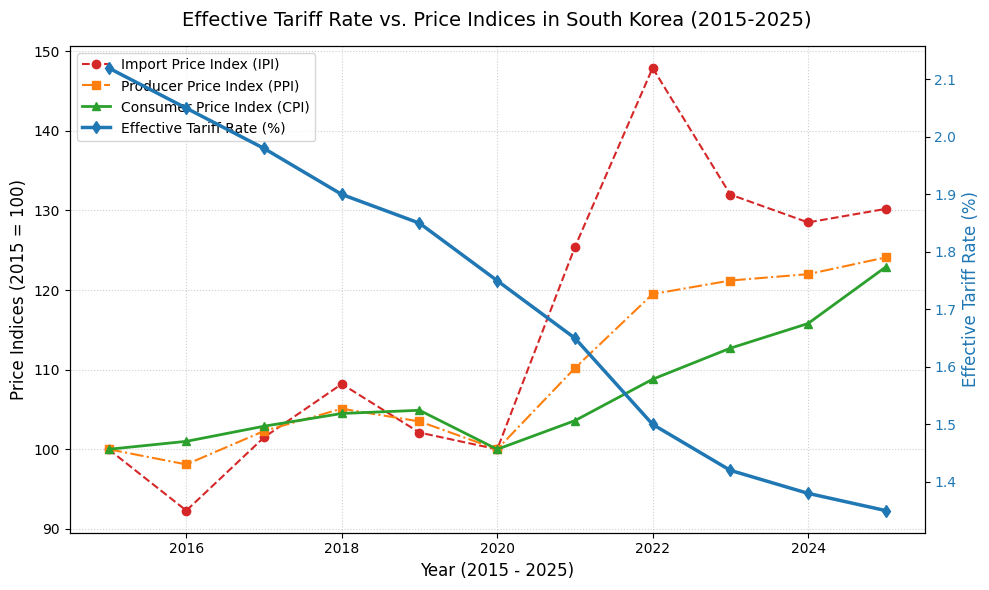

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. 데이터 불러오기 (실제 파일명에 맞게 경로를 수정해주세요)
# 예: ip = pd.read_csv('수입물가지수.csv')
# 아래는 가상의 예시 데이터프레임 구조를 가정합니다. 실제 보유하신 데이터 컬럼명에 맞춰주세요.

# 만약 하나의 통합된 CSV 파일이 있다면 아래와 같이 읽어옵니다.
# df = pd.read_csv('tariff_price_data.csv')

# --- [참고] 직접 데이터 배열로 테스트해보고 싶으실 때 아래 코드를 그대로 실행해보세요 ---
years = list(range(2015, 2026))
data = {
    'Year': years,
    'Effective_Tariff': [
        2.12, 2.05, 1.98, 1.90, 1.85, 1.75, 1.65, 1.50, 1.42, 1.38, 1.35
    ],  # 실효관세율 예시 (%)
    'Import_Price': [
        100.0, 92.3, 101.5, 108.2, 102.1, 100.0, 125.4, 147.9, 132.0, 128.5, 130.2
    ],  # 수입물가지수 (2015=100)
    'Producer_Price': [
        100.0, 98.1, 102.3, 105.1, 103.5, 100.0, 110.2, 119.5, 121.2, 122.0, 124.1
    ],  # 생산자물가지수
    'Consumer_Price': [
        100.0, 101.0, 102.9, 104.5, 104.9, 100.0, 103.6, 108.8, 112.7, 115.8, 122.9
    ],  # 소비자물가지수
}
df = pd.DataFrame(data)

# 2. 이중 축(Dual-Axis) 그래프 그리기 설정
fig, ax1 = plt.subplots(figsize=(10, 6))

# 왼쪽 Y축: 물가지수 (수입·생산자·소비자)
ax1.plot(
    df['Year'],
    df['Import_Price'],
    color='tab:red',
    linestyle='--',
    marker='o',
    label='Import Price Index (IPI)',
)
ax1.plot(
    df['Year'],
    df['Producer_Price'],
    color='tab:orange',
    linestyle='-.',
    marker='s',
    label='Producer Price Index (PPI)',
)
ax1.plot(
    df['Year'],
    df['Consumer_Price'],
    color='tab:green',
    linestyle='-',
    marker='^',
    linewidth=2,
    label='Consumer Price Index (CPI)',
)

ax1.set_xlabel('Year (2015 - 2025)', fontsize=12)
ax1.set_ylabel('Price Indices (2015 = 100)', fontsize=12, color='black')
ax1.tick_params(axis='y', labelcolor='black')
ax1.grid(True, linestyle=':', alpha=0.6)

# 오른쪽 Y축: 실효관세율
ax2 = ax1.twinx()
ax2.plot(
    df['Year'],
    df['Effective_Tariff'],
    color='tab:blue',
    linestyle='-',
    marker='d',
    linewidth=2.5,
    label='Effective Tariff Rate (%)',
)
ax2.set_ylabel('Effective Tariff Rate (%)', fontsize=12, color='tab:blue')
ax2.tick_params(axis='y', labelcolor='tab:blue')

# 3. 그래프 제목 및 범례 통합
plt.title(
    'Effective Tariff Rate vs. Price Indices in South Korea (2015-2025)',
    fontsize=14,
    pad=15,
)

# 양쪽 축의 범례(Legend)를 하나로 합치기
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(
    lines_1 + lines_2, labels_1 + labels_2, loc='upper left', frameon=True
)

plt.tight_layout()

# 4. 이미지로 저장 및 출력
plt.savefig('tariff_price_indices_2015_2025.png', dpi=300)
plt.show()